# Task 6: SalaryInsight - Model Evaluation
Evaluate the model using accuracy, precision, recall and F1-score on different test sets, check the effect of class imbalance, and visualize the metrics.

## Step 1: Import libraries

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

## Step 2: Load and clean the data

In [2]:
df = pd.read_csv("employee_data.csv")

# fill missing values with median
df["Performance_Rating"] = df["Performance_Rating"].fillna(df["Performance_Rating"].median())
df["Training_Hours"] = df["Training_Hours"].fillna(df["Training_Hours"].median())

# target: High = 1, Low = 0
df["Satisfaction"] = df["Satisfaction"].map({"Low": 0, "High": 1})

# text columns -> numbers
df = pd.get_dummies(df, columns=["Department", "Education", "City_Tier"], drop_first=True)

X = df.drop("Satisfaction", axis=1)
y = df["Satisfaction"]
df.head()

,Age,Experience_Years,Performance_Rating,Weekly_Hours,Training_Hours,Certifications,Work_Life_Balance,Salary_LPA,Satisfaction,Department_Finance,Department_HR,Department_Marketing,Department_Operations,Department_Sales,Education_Diploma,Education_Masters,Education_PhD,City_Tier_Tier2,City_Tier_Tier3
0,41,17,2.4,42.0,56.0,0,5.0,25.00,1,False,False,True,False,False,False,False,True,True,False
1,39,13,3.7,49.0,12.0,2,3.1,19.41,0,False,False,False,False,True,False,False,False,False,False
2,24,2,3.5,45.0,8.0,2,3.9,8.41,0,False,False,False,True,False,True,False,False,False,True
3,26,0,3.7,34.0,5.0,1,4.0,19.83,0,True,False,False,False,False,False,True,False,False,False
4,44,19,3.8,40.0,56.0,0,3.2,28.35,1,False,False,False,False,False,False,False,False,True,False


## Step 3: Check class imbalance

In [3]:
print(y.value_counts())
print()
print((y.value_counts(normalize=True) * 100).round(1))

Satisfaction
0    1464
1     536
Name: count, dtype: int64

Satisfaction
0    73.2
1    26.8
Name: proportion, dtype: float64


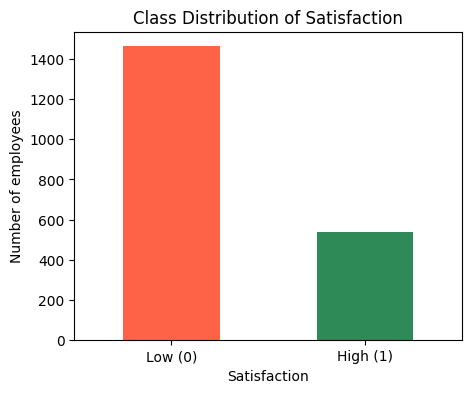

In [4]:
y.value_counts().sort_index().plot(kind="bar", color=["tomato", "seagreen"], figsize=(5, 4))
plt.xticks([0, 1], ["Low (0)", "High (1)"], rotation=0)
plt.title("Class Distribution of Satisfaction")
plt.ylabel("Number of employees")
plt.show()

About 73% of employees are Low and 27% are High, so the data is **imbalanced**.

## Step 4: Function to calculate the metrics

In [5]:
def get_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred),
    }

## Step 5: Evaluate on different test sets
I change the test size and the random seed so each run uses a different test set. The model uses `max_depth=8` and `min_samples_leaf=5` to reduce overfitting.

In [6]:
results = []

for test_size in [0.2, 0.3, 0.4]:
    for seed in [1, 42]:
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=test_size, random_state=seed, stratify=y
        )

        model = RandomForestClassifier(
            n_estimators=100, max_depth=8, min_samples_leaf=5, random_state=42
        )
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        row = get_metrics(y_test, y_pred)
        row["Test Set"] = f"size={test_size}, seed={seed}"
        results.append(row)

results_df = pd.DataFrame(results)
results_df = results_df[["Test Set", "Accuracy", "Precision", "Recall", "F1-score"]]
results_df.round(4)

,Test Set,Accuracy,Precision,Recall,F1-score
0,"size=0.2, seed=1",0.8300,0.7671,0.5234,0.6222
1,"size=0.2, seed=42",0.8300,0.7746,0.5140,0.6180
2,"size=0.3, seed=1",0.8300,0.7864,0.5031,0.6136
3,"size=0.3, seed=42",0.8300,0.7565,0.5404,0.6304
4,"size=0.4, seed=1",0.8275,0.7836,0.4907,0.6034
5,"size=0.4, seed=42",0.8300,0.7532,0.5421,0.6304


Accuracy stays almost the same (about 83%) on every test set, but recall is only about 50%.

## Step 6: Detailed report for one split

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=5, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred, target_names=["Low", "High"]))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

         Low       0.84      0.95      0.89       293
        High       0.77      0.51      0.62       107

    accuracy                           0.83       400
   macro avg       0.81      0.73      0.75       400
weighted avg       0.82      0.83      0.82       400

Confusion matrix:
[[277  16]
 [ 52  55]]


## Step 7: Effect of class imbalance
I train a second model with `class_weight="balanced"` which gives more importance to the smaller class (High).

In [8]:
model_bal = RandomForestClassifier(
    n_estimators=100, max_depth=8, min_samples_leaf=5,
    class_weight="balanced", random_state=42
)
model_bal.fit(X_train, y_train)
y_pred_bal = model_bal.predict(X_test)

imbalance_df = pd.DataFrame({
    "Normal model": get_metrics(y_test, y_pred),
    "Balanced model": get_metrics(y_test, y_pred_bal),
})
imbalance_df.round(4)

,Normal model,Balanced model
Accuracy,0.8300,0.8325
Precision,0.7746,0.6695
Recall,0.5140,0.7383
F1-score,0.6180,0.7022


With balancing, **recall for High goes up a lot** (the model finds more satisfied employees) but precision goes down a bit.

## Step 8: Visualizations

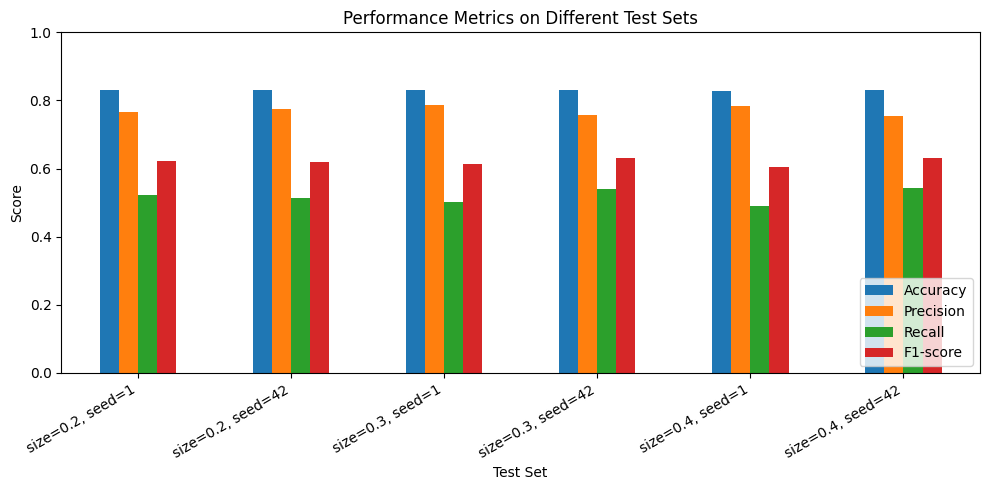

In [9]:
results_df.set_index("Test Set")[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(10, 5)
)
plt.title("Performance Metrics on Different Test Sets")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

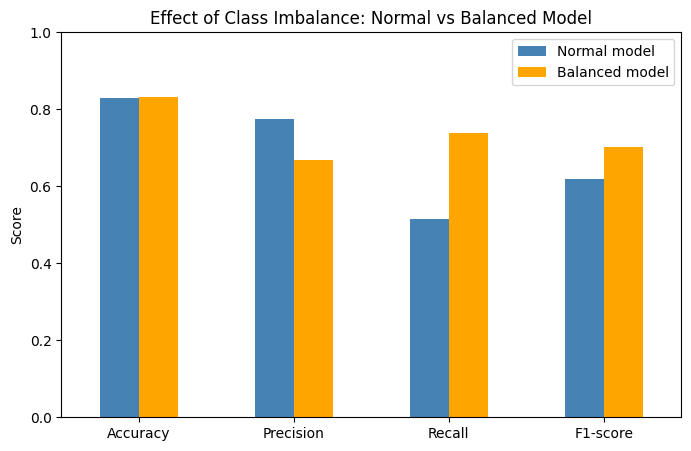

In [10]:
imbalance_df.plot(kind="bar", figsize=(8, 5), color=["steelblue", "orange"])
plt.title("Effect of Class Imbalance: Normal vs Balanced Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

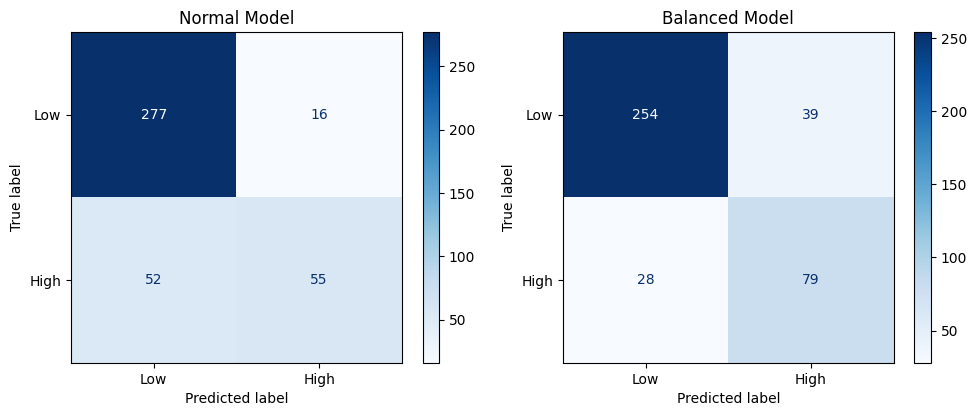

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Low", "High"]).plot(ax=axes[0], cmap="Blues")
axes[0].set_title("Normal Model")
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_bal), display_labels=["Low", "High"]).plot(ax=axes[1], cmap="Blues")
axes[1].set_title("Balanced Model")
plt.tight_layout()
plt.show()

## Conclusion
- Accuracy (about 83%) looks good, but it hides the class imbalance problem.
- The normal model has low recall for the High class (about 51%).
- Using `class_weight="balanced"` improves recall (about 74%) and F1-score (about 0.70) with a small drop in precision.
- So accuracy alone is not enough when classes are imbalanced.